# 1. Loading the Processed Dataset

In [2]:
import pandas as pd

df = pd.read_csv('processed_job_data.csv')
df.head()

,standardized_job_title,clean_job_title,company_name,job_country,employment_type,is_remote,job_description,job_source,posted_at_utc,normalized_job_description,extracted_skills,extracted_tools,extracted_technologies
0,data scientist,data scientist - open to all nationalities,Ajman University,AE,full-time,False,SUMMARY OF FUNCTIONS:\r\n\r\nThe Data Scientis...,indeed,2026-04-23 00:00:00+00:00,summary of functions:\r\n\r\nthe data scientis...,"['python', 'r']",['tableau'],['machine learning']
1,data scientist,"senior data scientist united arab emirates, dubai",Dataiku,AE,internship,False,"OverviewDataiku is The Universal AI Platform, ...",bebee,2026-04-25 00:00:00+00:00,"overviewdataiku is the universal ai platform, ...","['python', 'r']",[],['machine learning']
2,data scientist,data scientist-1205,Atribs Metscon,AE,full-time,False,JOB PURPOSE:\r\n\r\nLooking for Data & Artific...,bayt.com,2026-04-21 00:00:00+00:00,job purpose:\r\n\r\nlooking for data & artific...,['python'],[],['machine learning']
3,data scientist,junior genomics data scientist (gwas & qc),"United Arab Emirates University, Department of...",AE,full-time,False,A leading academic institution in Abu Dhabi se...,bebee,2026-04-23 00:00:00+00:00,a leading academic institution in abu dhabi se...,"['python', 'r']",[],[]
4,data scientist,data scientist-1205,Atribs Metscon Group,AE,full-time,False,"FAB AL Jaddaf, United Arab Emirates Salary: 23...",bebee,2026-04-25 00:00:00+00:00,"fab al jaddaf, united arab emirates salary: 23...",['python'],[],['machine learning']


## 1.1 Restoring Extracted Columns as Python Lists

In [3]:
df.dtypes

standardized_job_title         str
clean_job_title                str
company_name                   str
job_country                    str
employment_type                str
is_remote                     bool
job_description                str
job_source                     str
posted_at_utc                  str
normalized_job_description     str
extracted_skills               str
extracted_tools                str
extracted_technologies         str
dtype: object

In [4]:
import ast 

df['extracted_skills'] = df['extracted_skills'].apply(ast.literal_eval)
df['extracted_tools'] = df['extracted_tools'].apply(ast.literal_eval)
df['extracted_technologies'] = df['extracted_technologies'].apply(ast.literal_eval)

## 1.2 Verifying Restored Python Object Types

In [5]:
type(df['extracted_skills'][0])

list

## 1.3 Preparing Nested NLP Data for Analysis

### Observation

The extracted NLP columns contained nested list structures where multiple skills/tools/technologies were stored inside a single row.

Using `explode()` transformed each list element into an individual row, converting the data from a nested structure into a tabular format suitable for frequency analysis.

This transformation is necessary because functions like `value_counts()` operate correctly on atomic observations rather than entire Python lists.

In [6]:
df.explode('extracted_skills').head(5)


,standardized_job_title,clean_job_title,company_name,job_country,employment_type,is_remote,job_description,job_source,posted_at_utc,normalized_job_description,extracted_skills,extracted_tools,extracted_technologies
0,data scientist,data scientist - open to all nationalities,Ajman University,AE,full-time,False,SUMMARY OF FUNCTIONS:\r\n\r\nThe Data Scientis...,indeed,2026-04-23 00:00:00+00:00,summary of functions:\r\n\r\nthe data scientis...,python,[tableau],[machine learning]
0,data scientist,data scientist - open to all nationalities,Ajman University,AE,full-time,False,SUMMARY OF FUNCTIONS:\r\n\r\nThe Data Scientis...,indeed,2026-04-23 00:00:00+00:00,summary of functions:\r\n\r\nthe data scientis...,r,[tableau],[machine learning]
1,data scientist,"senior data scientist united arab emirates, dubai",Dataiku,AE,internship,False,"OverviewDataiku is The Universal AI Platform, ...",bebee,2026-04-25 00:00:00+00:00,"overviewdataiku is the universal ai platform, ...",python,[],[machine learning]
1,data scientist,"senior data scientist united arab emirates, dubai",Dataiku,AE,internship,False,"OverviewDataiku is The Universal AI Platform, ...",bebee,2026-04-25 00:00:00+00:00,"overviewdataiku is the universal ai platform, ...",r,[],[machine learning]
2,data scientist,data scientist-1205,Atribs Metscon,AE,full-time,False,JOB PURPOSE:\r\n\r\nLooking for Data & Artific...,bayt.com,2026-04-21 00:00:00+00:00,job purpose:\r\n\r\nlooking for data & artific...,python,[],[machine learning]


## 1.4 Frequency Analysis on Exploded NLP Columns

### Observation

- Python is the most frequently requested skill across the analyzed job postings, followed by SQL and R.
- Tableau is the dominant visualization/reporting tool, while Power BI appears less frequently.
- Machine Learning is the most demanded technology area, followed by Deep Learning and NLP.
- These frequency distributions help identify the most in-demand technical competencies in the current job market dataset.
- Frequency analysis provides a foundation for deeper role-based and market trend analysis in later stages of the project.

In [7]:
skills_count = df.explode('extracted_skills')['extracted_skills'].value_counts()
tool_count = df.explode('extracted_tools')['extracted_tools'].value_counts()
technologies_count = df.explode('extracted_technologies')['extracted_technologies'].value_counts()

In [8]:
print(skills_count)
print(tool_count)
print(technologies_count)   

extracted_skills
python    36
sql       28
r         12
Name: count, dtype: int64
extracted_tools
tableau    15
powerbi     2
Name: count, dtype: int64
extracted_technologies
machine learning    24
deep learning       10
nlp                  6
Name: count, dtype: int64


## 1.5 Understanding Frequency Distribution Limitations

### Analytical Note

- The extraction pipeline uses `re.search()`, which checks whether a term appears anywhere in the job description.
- Because of this, each skill/tool/technology is extracted only once per job posting, even if it appears multiple times in the same text.
- Therefore, the frequency counts represent job-level demand occurrence, not raw mention frequency.
- This makes the analysis more suitable for job market intelligence because each job posting contributes only one count per extracted term.

## 1.6 Comparing Skill Demand Across Job Roles

### Observation

- Role-based frequency analysis reveals clear specialization patterns between job categories.
- Data Scientist roles show stronger demand for Python, Machine Learning, Deep Learning, and NLP-related technologies.
- Data Analyst roles are more strongly associated with SQL, Tableau, and reporting-oriented skills.
- Segmenting skill demand by job role provides more accurate market intelligence than global frequency analysis alone.
- This analysis helps identify the technical competency profile associated with each role category.

In [9]:
skills_per_job = df.explode('extracted_skills').groupby('standardized_job_title')['extracted_skills'].value_counts()
tools_per_job = df.explode('extracted_tools').groupby('standardized_job_title')['extracted_tools'].value_counts()
technologies_per_job = df.explode('extracted_technologies').groupby('standardized_job_title')['extracted_technologies'].value_counts()

In [10]:
print(skills_per_job)
print(tools_per_job)
print(technologies_per_job)

standardized_job_title  extracted_skills
data analyst            sql                 16
                        python              12
                        r                    5
data scientist          python              24
                        sql                 12
                        r                    7
Name: count, dtype: int64
standardized_job_title  extracted_tools
data analyst            tableau            12
                        powerbi             2
data scientist          tableau             3
Name: count, dtype: int64
standardized_job_title  extracted_technologies
data analyst            machine learning           1
                        deep learning              1
data scientist          machine learning          23
                        deep learning              9
                        nlp                        6
Name: count, dtype: int64


## 1.7 Identifying Top Skills Per Job Role

### Observation

- Data Analyst roles show stronger demand for SQL as the dominant technical skill and Tableau as the primary reporting and visualization tool.
- Data Scientist roles are more strongly associated with Python and Machine Learning-related technologies.
- Tableau appears in both roles, indicating that data visualization remains important across multiple data-oriented career paths.
- Machine Learning technologies are significantly more dominant in Data Scientist roles compared to Data Analyst positions.
- Top-N role segmentation helps identify the core technical stack associated with each job category.

In [11]:
top_skills_per_job = skills_per_job.groupby(level=0).head(3)
top_tools_per_job = tools_per_job.groupby(level=0).head(3)
top_technologies_per_job = technologies_per_job.groupby(level=0).head(3)

In [12]:
print(top_skills_per_job)
print(top_tools_per_job)
print(top_technologies_per_job)

standardized_job_title  extracted_skills
data analyst            sql                 16
                        python              12
                        r                    5
data scientist          python              24
                        sql                 12
                        r                    7
Name: count, dtype: int64
standardized_job_title  extracted_tools
data analyst            tableau            12
                        powerbi             2
data scientist          tableau             3
Name: count, dtype: int64
standardized_job_title  extracted_technologies
data analyst            machine learning           1
                        deep learning              1
data scientist          machine learning          23
                        deep learning              9
                        nlp                        6
Name: count, dtype: int64


## 1.8 Converting MultiIndex Results into DataFrames

### Observation

- The role-based NLP frequency results were converted from MultiIndex Series into structured DataFrames.
- Each row now represents one job role and one extracted term with its corresponding count.
- This flat tabular format is easier to filter, visualize, export, and reuse in later analysis.
- Converting aggregated outputs into DataFrames prepares the results for charts, reporting, and dashboard-style analysis.

In [13]:
top_skills_df = top_skills_per_job.to_frame().reset_index()
top_tools_df = top_tools_per_job.to_frame().reset_index()
top_technologies_df = top_technologies_per_job.to_frame().reset_index()

In [14]:
top_skills_df

,standardized_job_title,extracted_skills,count
0,data analyst,sql,16
1,data analyst,python,12
2,data analyst,r,5
3,data scientist,python,24
4,data scientist,sql,12
5,data scientist,r,7


In [15]:
top_skills_df.head()

,standardized_job_title,extracted_skills,count
0,data analyst,sql,16
1,data analyst,python,12
2,data analyst,r,5
3,data scientist,python,24
4,data scientist,sql,12


## 1.8 Converting Aggregated NLP Results into Structured DataFrames

In [16]:
top_tools_df.head()

,standardized_job_title,extracted_tools,count
0,data analyst,tableau,12
1,data analyst,powerbi,2
2,data scientist,tableau,3


In [17]:
top_technologies_df.head()

,standardized_job_title,extracted_technologies,count
0,data analyst,machine learning,1
1,data analyst,deep learning,1
2,data scientist,machine learning,23
3,data scientist,deep learning,9
4,data scientist,nlp,6


## 1.9 Preparing NLP Results for Visualization

### Observation

- The transformed NLP analysis DataFrames follow a clean tabular structure suitable for visualization.
- Categorical variables such as job roles and extracted skills are separated into explicit columns, while frequency values are stored as numerical metrics.
- The dataset is already in a tidy format, making it directly compatible with visualization and reporting workflows.
- No additional preprocessing is required before plotting the role-based NLP analysis results.

In [18]:
top_skills_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   standardized_job_title  6 non-null      str  
 1   extracted_skills        6 non-null      str  
 2   count                   6 non-null      int64
dtypes: int64(1), str(2)
memory usage: 276.0 bytes


In [19]:
top_tools_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   standardized_job_title  3 non-null      str  
 1   extracted_tools         3 non-null      str  
 2   count                   3 non-null      int64
dtypes: int64(1), str(2)
memory usage: 204.0 bytes


In [20]:
top_technologies_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   standardized_job_title  5 non-null      str  
 1   extracted_technologies  5 non-null      str  
 2   count                   5 non-null      int64
dtypes: int64(1), str(2)
memory usage: 252.0 bytes


## 2.0 Visualizing Role-Based NLP Demand Analysis

In [21]:
data_scientist_skills = top_skills_df[top_skills_df['standardized_job_title']=='data scientist']

In [22]:
data_scientist_skills.head()

,standardized_job_title,extracted_skills,count
3,data scientist,python,24
4,data scientist,sql,12
5,data scientist,r,7


## 2.1 Visualizing Top Skills for Data Scientist Roles

### Observation

- The visualization shows that Python is the most dominant skill required for Data Scientist roles, followed by SQL and R.
- Python appears significantly more frequently than the other extracted skills, highlighting its importance in Data Science-related job postings.
- SQL remains highly demanded, indicating the importance of data querying and database skills in Data Scientist positions.
- R appears less frequently but still represents a relevant analytical programming language within the dataset.

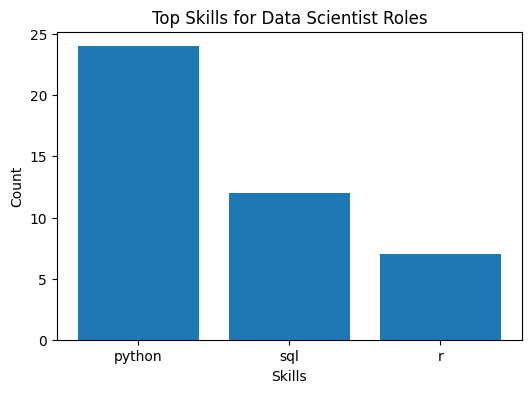

In [23]:
import matplotlib.pyplot as plt

x = data_scientist_skills['extracted_skills']
y = data_scientist_skills['count']

plt.figure(figsize=(6,4))

plt.bar(x,y)

plt.xlabel('Skills')
plt.ylabel('Count')
plt.title('Top Skills for Data Scientist Roles')
plt.show()

## 2.2 Automating Role-Based Skill Visualizations

### Observation

- The visualization workflow was generalized using a reusable plotting function, allowing role-based charts to be generated dynamically for multiple NLP categories.
- This approach improves scalability, reduces repetitive plotting code, and makes the visualization pipeline easier to maintain.
- The generated charts clearly highlight differences in technical demand across job roles.
- SQL appears more dominant in Data Analyst positions, while Python is significantly more dominant in Data Scientist roles.
- Automating the visualization process improves analytical consistency across skills, tools, and technologies.

In [24]:
def plot_role_distribution(dataframe, column_name, category_name, metric_column, y_label):

    job_roles = dataframe['standardized_job_title'].unique()

    for role in job_roles:
        filtered_df = dataframe[
            dataframe['standardized_job_title'] == role]

        x = filtered_df[column_name]
        y = filtered_df[metric_column]

        plt.figure(figsize=(6,4))

        bar = plt.bar(x,y)
        plt.bar_label(bar)

        plt.xlabel(category_name)
        plt.ylabel(y_label)
        plt.title(f'Relative {category_name} Demand for {role.title()} Roles')
        plt.show()                                                  

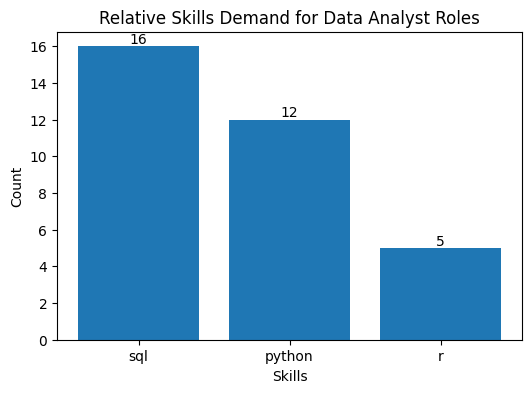

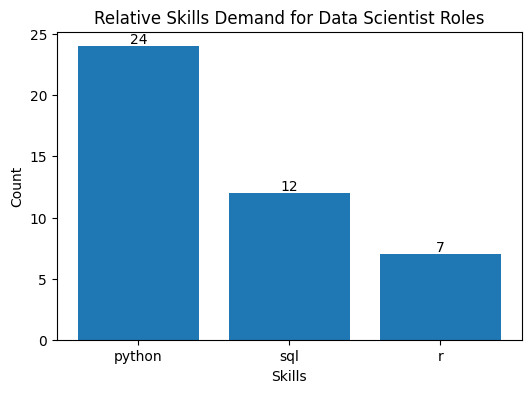

In [25]:
plot_role_distribution(top_skills_df, 'extracted_skills', 'Skills', 'count', 'Count')

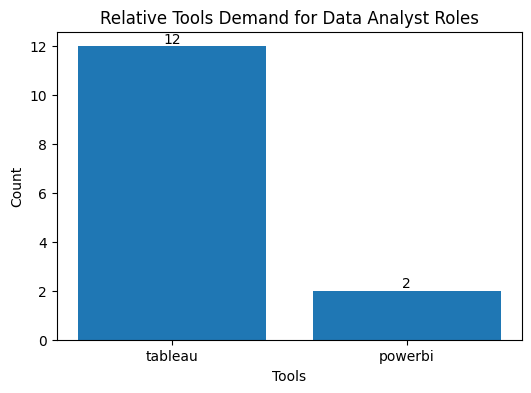

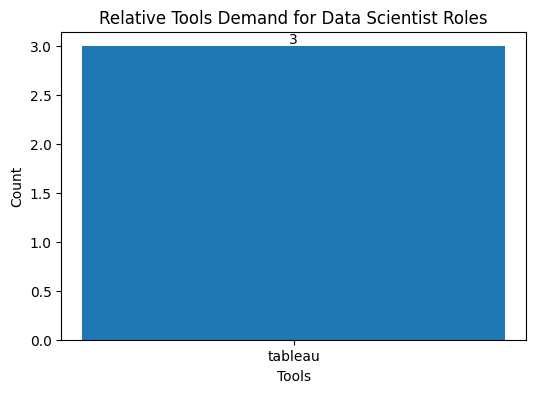

In [26]:
plot_role_distribution(top_tools_df, 'extracted_tools', 'Tools', 'count','Count')

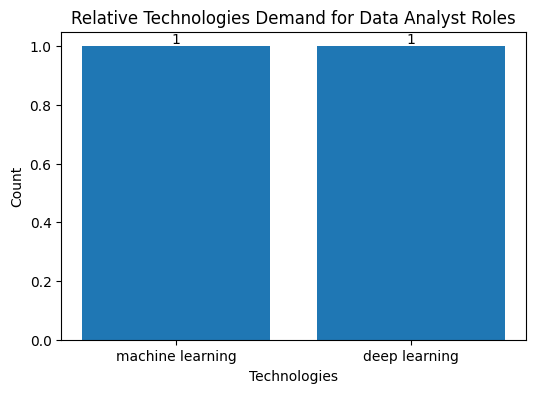

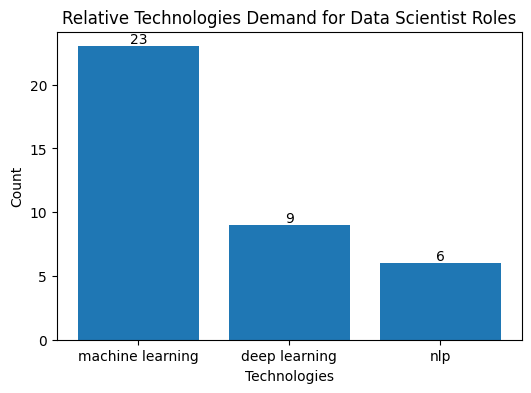

In [27]:
plot_role_distribution(top_technologies_df, 'extracted_technologies', 'Technologies', 'count', 'Count')

## 2.5 Comparing Relative Skill Demand Across Roles

In [28]:
job_role_counts = df['standardized_job_title'].value_counts()
job_role_counts

standardized_job_title
data scientist    28
data analyst      26
Name: count, dtype: int64

In [29]:
job_role_counts.to_frame().reset_index()

,standardized_job_title,count
0,data scientist,28
1,data analyst,26


In [30]:
merged_skills_df = pd.merge(job_role_counts, top_skills_df, on='standardized_job_title')
merged_skills_df = merged_skills_df.rename(columns={
    'count_x': 'total_postings',
    'count_y': 'skill_count'
})
merged_skills_df['skill_percentage'] = (
    merged_skills_df['skill_count'] / merged_skills_df['total_postings']
) * 100

merged_skills_df

,standardized_job_title,total_postings,extracted_skills,skill_count,skill_percentage
0,data scientist,28,python,24,85.714286
1,data scientist,28,sql,12,42.857143
2,data scientist,28,r,7,25.000000
3,data analyst,26,sql,16,61.538462
4,data analyst,26,python,12,46.153846
5,data analyst,26,r,5,19.230769


In [31]:
merged_tools_df = pd.merge(job_role_counts, top_tools_df, on='standardized_job_title')
merged_tools_df = merged_tools_df.rename(columns={
    'count_x': 'total_postings',
    'count_y': 'tool_count'
})
merged_tools_df['tools_percentage'] = (
    merged_tools_df['tool_count'] / merged_tools_df['total_postings']
) * 100
merged_tools_df

,standardized_job_title,total_postings,extracted_tools,tool_count,tools_percentage
0,data scientist,28,tableau,3,10.714286
1,data analyst,26,tableau,12,46.153846
2,data analyst,26,powerbi,2,7.692308


In [32]:
merged_technologies_df = pd.merge(job_role_counts, top_technologies_df, on='standardized_job_title')
merged_technologies_df = merged_technologies_df.rename(columns={
    'count_x': 'total_postings',
    'count_y': 'technologies_count'
})
merged_technologies_df['technology_percentage'] = (
    merged_technologies_df['technologies_count'] / merged_technologies_df['total_postings']
) * 100
merged_technologies_df

,standardized_job_title,total_postings,extracted_technologies,technologies_count,technology_percentage
0,data scientist,28,machine learning,23,82.142857
1,data scientist,28,deep learning,9,32.142857
2,data scientist,28,nlp,6,21.428571
3,data analyst,26,machine learning,1,3.846154
4,data analyst,26,deep learning,1,3.846154


## 2.6 Visualizing Relative Skill Demand by Percentage

### Observation

- Percentage-based visualization provides a normalized comparison of skill demand across job roles.
- Python appears in a significantly higher percentage of Data Scientist job postings, while SQL is more dominant within Data Analyst roles.
- Relative demand analysis reduces bias caused by differences in the total number of postings between roles.
- Normalized skill percentages provide a more reliable representation of role-specific technical requirements compared to raw frequency counts alone.

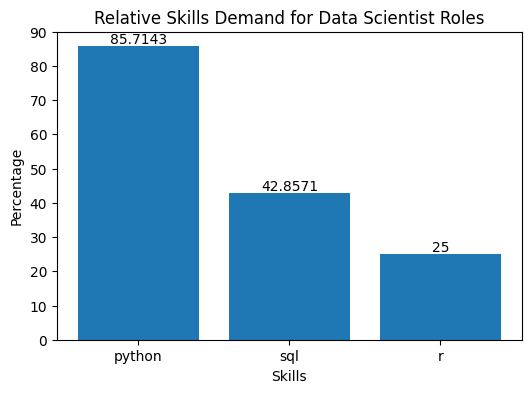

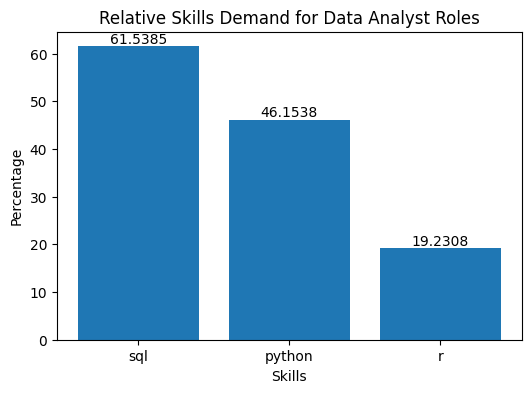

In [33]:
plot_role_distribution(merged_skills_df, 'extracted_skills', 'Skills', 'skill_percentage', 'Percentage')

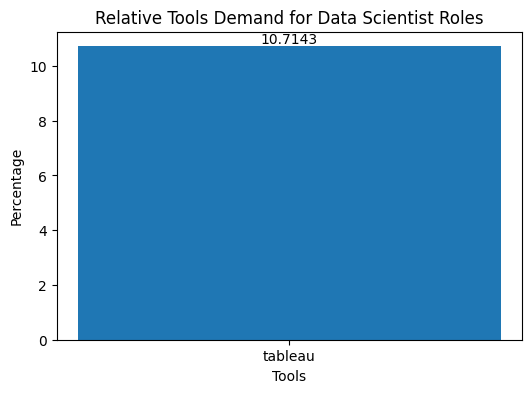

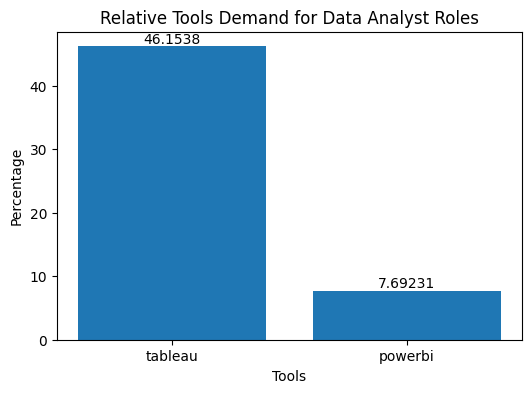

In [34]:
plot_role_distribution(merged_tools_df, 'extracted_tools', 'Tools', 'tools_percentage', 'Percentage')

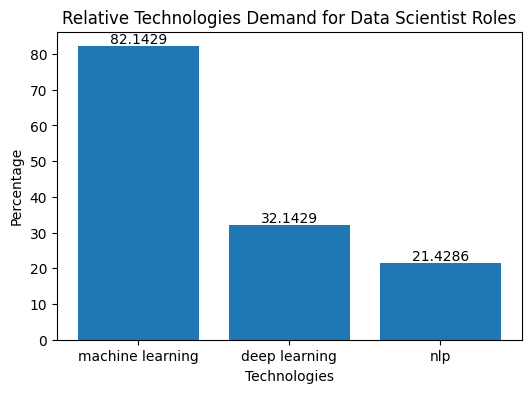

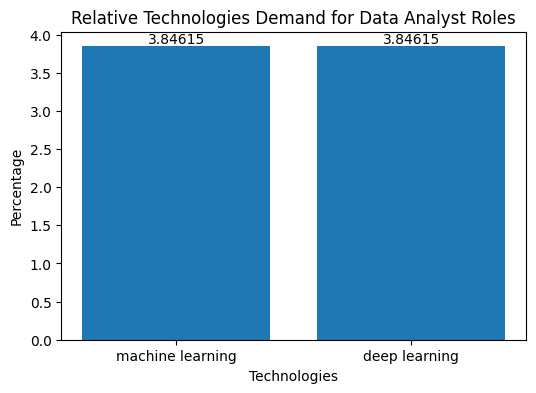

In [35]:
plot_role_distribution(merged_technologies_df, 'extracted_technologies', 'Technologies', 'technology_percentage', 'Percentage')

## 2.7 Comparing Skills, Tools, and Technologies Holistically

### Observation

- Skills, tools, and technologies were standardized into a unified analytical structure and combined into a single competency profile dataset.
- Schema standardization enabled multiple NLP extraction categories to be integrated consistently using a long-format tabular structure.
- The unified competency dataset provides a more holistic view of the technical requirements associated with each job role.
- Combining multiple competency categories improves downstream analysis, comparison, and visualization workflows.

In [36]:
skills_profile = merged_skills_df[
    [
        'standardized_job_title',
        'extracted_skills',
        'skill_percentage'
    ]
].rename(columns={
    'extracted_skills': 'term',
    'skill_percentage': 'percentage'
})

skills_profile['category'] = 'Skill'

skills_profile

,standardized_job_title,term,percentage,category
0,data scientist,python,85.714286,Skill
1,data scientist,sql,42.857143,Skill
2,data scientist,r,25.000000,Skill
3,data analyst,sql,61.538462,Skill
4,data analyst,python,46.153846,Skill
5,data analyst,r,19.230769,Skill


In [37]:
tools_profile = merged_tools_df[
    [
        'standardized_job_title',
        'extracted_tools',
        'tools_percentage'
    ]
].rename(columns={
    'extracted_tools': 'term',
    'tools_percentage': 'percentage'
})

tools_profile['category'] = 'Tool'
tools_profile

,standardized_job_title,term,percentage,category
0,data scientist,tableau,10.714286,Tool
1,data analyst,tableau,46.153846,Tool
2,data analyst,powerbi,7.692308,Tool


In [38]:
technology_profile = merged_technologies_df[
    [
        'standardized_job_title',
        'extracted_technologies',
        'technology_percentage'
    ]
].rename(columns={
    'extracted_technologies': 'term',
    'technology_percentage': 'percentage'
})

technology_profile['category'] = 'Technology'
technology_profile

,standardized_job_title,term,percentage,category
0,data scientist,machine learning,82.142857,Technology
1,data scientist,deep learning,32.142857,Technology
2,data scientist,nlp,21.428571,Technology
3,data analyst,machine learning,3.846154,Technology
4,data analyst,deep learning,3.846154,Technology


In [39]:
role_competency_profile = pd.concat([skills_profile, tools_profile, technology_profile], axis=0, ignore_index=True)
role_competency_profile

,standardized_job_title,term,percentage,category
0,data scientist,python,85.714286,Skill
1,data scientist,sql,42.857143,Skill
2,data scientist,r,25.000000,Skill
3,data analyst,sql,61.538462,Skill
4,data analyst,python,46.153846,Skill
5,data analyst,r,19.230769,Skill
6,data scientist,tableau,10.714286,Tool
7,data analyst,tableau,46.153846,Tool
8,data analyst,powerbi,7.692308,Tool
9,data scientist,machine learning,82.142857,Technology


In [40]:
role_competency_profile['category'].value_counts()

category
Skill         6
Technology    5
Tool          3
Name: count, dtype: int64

## 2.8 Exploring Competency Composition by Role

In [41]:
role_competency_profile

,standardized_job_title,term,percentage,category
0,data scientist,python,85.714286,Skill
1,data scientist,sql,42.857143,Skill
2,data scientist,r,25.000000,Skill
3,data analyst,sql,61.538462,Skill
4,data analyst,python,46.153846,Skill
5,data analyst,r,19.230769,Skill
6,data scientist,tableau,10.714286,Tool
7,data analyst,tableau,46.153846,Tool
8,data analyst,powerbi,7.692308,Tool
9,data scientist,machine learning,82.142857,Technology


In [42]:
role_category_summary = role_competency_profile.groupby(['standardized_job_title', 'category'])['percentage'].sum().reset_index()
role_category_summary

,standardized_job_title,category,percentage
0,data analyst,Skill,126.923077
1,data analyst,Technology,7.692308
2,data analyst,Tool,53.846154
3,data scientist,Skill,153.571429
4,data scientist,Technology,135.714286
5,data scientist,Tool,10.714286


### Observation

- Both Data Scientist and Data Analyst roles show high cumulative intensity in core technical skills.
- Data Scientist roles demonstrate significantly higher technology-related intensity, reflecting stronger association with Machine Learning and NLP domains.
- Data Analyst roles show substantially higher tool-related intensity, indicating greater emphasis on reporting and visualization platforms such as Tableau.
- The grouped comparison clearly highlights the specialization differences between analytical and machine learning-oriented career paths.

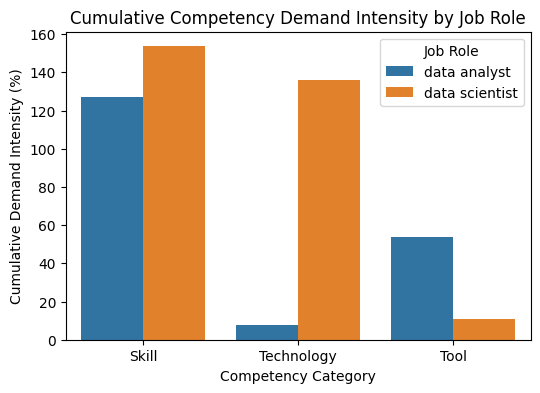

In [43]:
import seaborn as sns

plt.figure(figsize=(6,4))
sns.barplot(data = role_category_summary,
            x='category',
            y='percentage',
            hue='standardized_job_title')

plt.xlabel('Competency Category')
plt.ylabel('Cumulative Demand Intensity (%)')
plt.legend(title='Job Role')
plt.title('Cumulative Competency Demand Intensity by Job Role')

plt.show()

## 2.9 Summarizing Key NLP Market Intelligence Insights

### Key Insights

- SQL is the dominant skill for Data Analyst roles, appearing in approximately 61% of the analyzed job postings.
- Python is the dominant skill for Data Scientist roles, appearing in approximately 86% of the analyzed postings.
- Data Scientist roles demonstrate significantly higher technology-related competency intensity, particularly in Machine Learning and NLP domains.
- Data Analyst roles show stronger emphasis on tool-oriented competencies such as Tableau and reporting-related platforms.
- Percentage-based analysis provides a more reliable comparison than raw counts because it normalizes demand relative to the total number of postings per role.
- Relative demand analysis improves interpretation by showing how frequently competencies appear within each job category rather than relying only on absolute occurrence counts.

## 3.0 Preparing NLP Features for Machine Learning

In [44]:
df.explode('extracted_skills')['extracted_skills'].unique()

<StringArray>
['python', 'r', 'sql', nan]
Length: 4, dtype: str

In [45]:
ML_Skills = df.explode('extracted_skills')['extracted_skills'].value_counts().to_frame().reset_index()
ML_Skills = ML_Skills.rename(columns={
    'extracted_skills' : 'Skills'
})
ML_Skills

,Skills,count
0,python,36
1,sql,28
2,r,12


In [46]:
ML_Skills[ML_Skills['count'] >= 5]

,Skills,count
0,python,36
1,sql,28
2,r,12


## 3.1 Encoding NLP Skill Features into Machine Learning Variables

In [47]:
from sklearn.preprocessing import MultiLabelBinarizer

mlb_skills = MultiLabelBinarizer()

skills_matrix = mlb_skills.fit_transform(df['extracted_skills'])
mlb_skills.classes_

print(skills_matrix)
print(mlb_skills.classes_)

[[1 1 0]
 [1 1 0]
 [1 0 0]
 [1 1 0]
 [1 0 0]
 [1 1 1]
 [1 0 0]
 [1 1 1]
 [1 0 0]
 [1 0 0]
 [1 0 0]
 [1 0 1]
 [1 0 1]
 [1 0 1]
 [1 0 1]
 [1 0 0]
 [1 0 1]
 [0 0 0]
 [0 0 0]
 [1 0 1]
 [1 1 1]
 [0 0 0]
 [1 1 1]
 [0 0 0]
 [1 0 1]
 [1 0 0]
 [1 0 0]
 [1 0 1]
 [0 0 0]
 [0 0 1]
 [0 0 0]
 [1 0 1]
 [1 1 1]
 [0 0 0]
 [1 0 1]
 [0 1 0]
 [1 1 1]
 [0 0 0]
 [1 0 1]
 [0 0 0]
 [0 0 1]
 [1 0 1]
 [1 0 1]
 [1 1 0]
 [1 1 1]
 [1 0 1]
 [0 0 1]
 [1 0 1]
 [1 0 1]
 [0 0 1]
 [0 0 1]
 [0 0 0]
 [0 0 0]
 [0 0 0]]
['python' 'r' 'sql']


In [48]:
skills_encoded_df = pd.DataFrame(
    data= skills_matrix,
    columns= mlb_skills.classes_
)
skills_encoded_df.head(5)

,python,r,sql
0,1,1,0
1,1,1,0
2,1,0,0
3,1,1,0
4,1,0,0


## 3.2 Integrating Encoded Skill Features into the Main Dataset

In [49]:
# Combine encoded skill features with the original dataset
ml_ready_df = pd.concat([df, skills_encoded_df], axis=1)

print(ml_ready_df.shape)
ml_ready_df.head()

(54, 16)


,standardized_job_title,clean_job_title,company_name,job_country,employment_type,is_remote,job_description,job_source,posted_at_utc,normalized_job_description,extracted_skills,extracted_tools,extracted_technologies,python,r,sql
0,data scientist,data scientist - open to all nationalities,Ajman University,AE,full-time,False,SUMMARY OF FUNCTIONS:\r\n\r\nThe Data Scientis...,indeed,2026-04-23 00:00:00+00:00,summary of functions:\r\n\r\nthe data scientis...,"[python, r]",[tableau],[machine learning],1,1,0
1,data scientist,"senior data scientist united arab emirates, dubai",Dataiku,AE,internship,False,"OverviewDataiku is The Universal AI Platform, ...",bebee,2026-04-25 00:00:00+00:00,"overviewdataiku is the universal ai platform, ...","[python, r]",[],[machine learning],1,1,0
2,data scientist,data scientist-1205,Atribs Metscon,AE,full-time,False,JOB PURPOSE:\r\n\r\nLooking for Data & Artific...,bayt.com,2026-04-21 00:00:00+00:00,job purpose:\r\n\r\nlooking for data & artific...,[python],[],[machine learning],1,0,0
3,data scientist,junior genomics data scientist (gwas & qc),"United Arab Emirates University, Department of...",AE,full-time,False,A leading academic institution in Abu Dhabi se...,bebee,2026-04-23 00:00:00+00:00,a leading academic institution in abu dhabi se...,"[python, r]",[],[],1,1,0
4,data scientist,data scientist-1205,Atribs Metscon Group,AE,full-time,False,"FAB AL Jaddaf, United Arab Emirates Salary: 23...",bebee,2026-04-25 00:00:00+00:00,"fab al jaddaf, united arab emirates salary: 23...",[python],[],[machine learning],1,0,0


## 3.3 Defining Features and Target for Machine Learning

In [50]:
# Define ML features and target variable
X = ml_ready_df[mlb_skills.classes_]
y = ml_ready_df['standardized_job_title']

In [51]:
print(X.head())
print(y.head())

   python  r  sql
0       1  1    0
1       1  1    0
2       1  0    0
3       1  1    0
4       1  0    0
0    data scientist
1    data scientist
2    data scientist
3    data scientist
4    data scientist
Name: standardized_job_title, dtype: str


## 3.4 Splitting Data into Training and Testing Sets

In [52]:
from sklearn.model_selection import train_test_split

#split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [53]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(43, 3) (43,)
(11, 3) (11,)


## 3.5 Training the First Machine Learning Model

In [54]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


## 3.6 Making Predictions and Evaluating Model Performance

In [55]:
y_pred = model.predict(X_test)
y_pred

array(['data scientist', 'data analyst', 'data scientist',
       'data scientist', 'data scientist', 'data scientist',
       'data analyst', 'data analyst', 'data scientist', 'data scientist',
       'data scientist'], dtype=object)

In [56]:
y_test.values

<StringArray>
['data scientist',   'data analyst',   'data analyst', 'data scientist',
   'data analyst', 'data scientist', 'data scientist',   'data analyst',
 'data scientist',   'data analyst', 'data scientist']
Length: 11, dtype: str

In [57]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 0.64


## 3.7 Inspecting Model Predictions

In [58]:
# Compare actual and predicted job roles
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})
comparison_df

,Actual,Predicted
19,data scientist,data scientist
49,data analyst,data analyst
48,data analyst,data scientist
12,data scientist,data scientist
44,data analyst,data scientist
5,data scientist,data scientist
17,data scientist,data analyst
52,data analyst,data analyst
3,data scientist,data scientist
32,data analyst,data scientist


## 3.8 Understanding Model Performance Beyond Accuracy

In [59]:
# Check target class distribution
ml_ready_df['standardized_job_title'].value_counts()

standardized_job_title
data scientist    28
data analyst      26
Name: count, dtype: int64

In [60]:
from sklearn.metrics import classification_report
report = classification_report(y_test, y_pred, output_dict=True)
print(report)

{'data analyst': {'precision': 0.6666666666666666, 'recall': 0.4, 'f1-score': 0.5, 'support': 5.0}, 'data scientist': {'precision': 0.625, 'recall': 0.8333333333333334, 'f1-score': 0.7142857142857143, 'support': 6.0}, 'accuracy': 0.6363636363636364, 'macro avg': {'precision': 0.6458333333333333, 'recall': 0.6166666666666667, 'f1-score': 0.6071428571428572, 'support': 11.0}, 'weighted avg': {'precision': 0.6439393939393939, 'recall': 0.6363636363636364, 'f1-score': 0.6168831168831169, 'support': 11.0}}


## 3.9 Understanding Confusion Matrix

In [61]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(model.classes_)
print(cm) #[ correct , wrong ]
          #[ wrong   , correct ]

['data analyst' 'data scientist']
[[2 3]
 [1 5]]


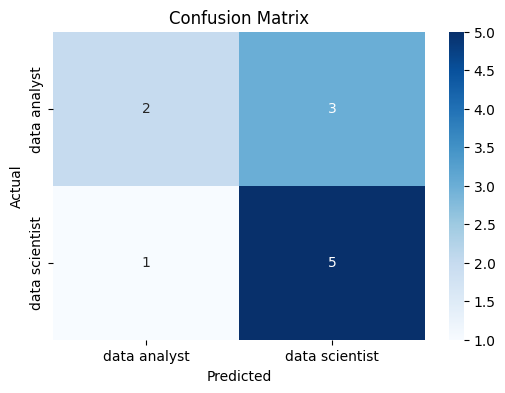

In [62]:
plt.figure(figsize=(6,4))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=model.classes_, yticklabels=model.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

## Observation

- `2` job postings were correctly classified as **Data Analyst**, representing **True Negatives (TN)** because the actual and predicted class were both non-data scientist roles.
- `5` job postings were correctly classified as **Data Scientist**, representing **True Positives (TP)** because the actual and predicted class matched the positive target class.
- `3` actual **Data Analyst** roles were incorrectly predicted as **Data Scientist**, representing **False Positives (FP)** where the model incorrectly favored the positive class.
- `1` actual **Data Scientist** role was incorrectly predicted as **Data Analyst**, representing a **False Negative (FN)** where the model failed to identify the positive class.
- The confusion matrix suggests the model performs better at identifying **Data Scientist** roles than **Data Analyst** roles, likely due to overlapping skill patterns between the two job categories.

## 3.10 Testing the Model on New Custom Data

## Observation

- The trained Logistic Regression model successfully predicted a custom unseen skill profile as **Data Scientist**, demonstrating the model’s ability to generalize beyond the original dataset.
- The prediction workflow confirmed that new input data must follow the same feature structure used during training, including identical column names, order, and binary encoding format.
- The result suggests that strong association with **Python** and **R** skills influenced the prediction toward a **Data Scientist** role.
- This step simulates a real-world machine learning use case, where a trained model receives new user inputs and generates predictions without knowing the true outcome beforehand.

In [63]:
new_profile = pd.DataFrame({
    'python': [1],
    'r': [1],
    'sql': [0]
})  
new_profile

,python,r,sql
0,1,1,0


In [64]:
## Predict job role for a new custom skill profile
model.predict(new_profile) 

array(['data scientist'], dtype=object)

## 3.11 Understanding Feature Importance in Logistic Regression

## Observation

- **Python** has the strongest positive influence toward **Data Scientist** predictions, indicating it is the most distinguishing skill in the model.
- **SQL** shows a negative influence, suggesting stronger association with **Data Analyst** roles.
- **R** has minimal impact on prediction decisions, indicating weak separation power between the two job roles in this dataset.
- The coefficient analysis improves model interpretability by explaining how individual skills influence classification outcomes.

In [65]:
print(model.classes_)
print(model.coef_)
print(X.columns)
#positive coefficient → pushes prediction toward second class
#negative coefficient → pushes prediction toward first class

['data analyst' 'data scientist']
[[ 1.65085576  0.12672816 -1.01645494]]
Index(['python', 'r', 'sql'], dtype='str')


## 3.12 Visualizing Logistic Regression Feature Importance

## Observation

- **Python** has the strongest influence in pushing predictions toward the **Data Scientist** class, making it the most important feature in the model.
- **R** has a small positive coefficient, indicating a weak influence toward **Data Scientist** predictions.
- **SQL** has a negative coefficient, meaning it pushes predictions toward the **Data Analyst** class.
- The coefficient values suggest that **Python** is the strongest differentiating skill, while **R** contributes only minimally to role separation in this dataset.

In [66]:
# Create feature importance DataFrame from logistic regression coefficients
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})
feature_importance_df

,Feature,Coefficient
0,python,1.650856
1,r,0.126728
2,sql,-1.016455


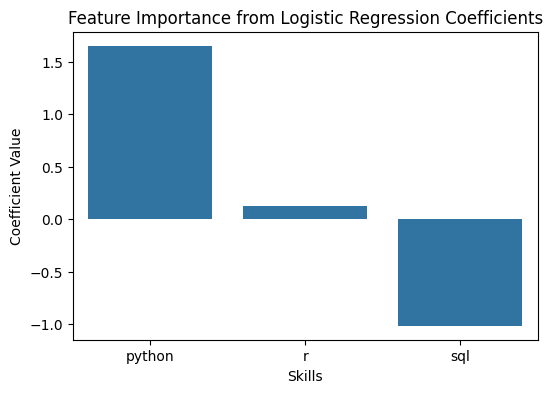

In [67]:
plt.figure(figsize=(6,4))

sns.barplot(data = feature_importance_df,
            x='Feature',
            y='Coefficient')

plt.xlabel('Skills')
plt.ylabel('Coefficient Value')
plt.title('Feature Importance from Logistic Regression Coefficients')
plt.show()

## 3.13 Improving the Model with More NLP Features

## Observation

- The improved feature set was successfully split into training and testing subsets using the same reproducible configuration.
- The training and testing data now contain **8 encoded features**, reflecting the integration of **skills**, **tools**, and **technologies**.
- The target variable remained unchanged, while the feature space expanded to provide richer predictive information.
- Repeating the train-test split after feature engineering is necessary to ensure consistency between the updated feature matrix and model training process.

In [68]:
mlb_tools = MultiLabelBinarizer()
tools_matrix = mlb_tools.fit_transform(df['extracted_tools'])


tools_encoded_df = pd.DataFrame(
    data= tools_matrix, 
    columns= mlb_tools.classes_
)
tools_encoded_df.head()

,powerbi,tableau
0,0,1
1,0,0
2,0,0
3,0,0
4,0,0


In [69]:
mlb_technology = MultiLabelBinarizer()
technology_matrix = mlb_technology.fit_transform(df['extracted_technologies'])

technology_encoded_df = pd.DataFrame(
    data = technology_matrix,
    columns = mlb_technology.classes_
)
technology_encoded_df.head()


,deep learning,machine learning,nlp
0,0,1,0
1,0,1,0
2,0,1,0
3,0,0,0
4,0,1,0


In [70]:
ml_ready_df_v2 = pd.concat([ml_ready_df, tools_encoded_df, technology_encoded_df], axis=1)
ml_ready_df_v2.head()

,standardized_job_title,clean_job_title,company_name,job_country,employment_type,is_remote,job_description,job_source,posted_at_utc,normalized_job_description,...,extracted_tools,extracted_technologies,python,r,sql,powerbi,tableau,deep learning,machine learning,nlp
0,data scientist,data scientist - open to all nationalities,Ajman University,AE,full-time,False,SUMMARY OF FUNCTIONS:\r\n\r\nThe Data Scientis...,indeed,2026-04-23 00:00:00+00:00,summary of functions:\r\n\r\nthe data scientis...,...,[tableau],[machine learning],1,1,0,0,1,0,1,0
1,data scientist,"senior data scientist united arab emirates, dubai",Dataiku,AE,internship,False,"OverviewDataiku is The Universal AI Platform, ...",bebee,2026-04-25 00:00:00+00:00,"overviewdataiku is the universal ai platform, ...",...,[],[machine learning],1,1,0,0,0,0,1,0
2,data scientist,data scientist-1205,Atribs Metscon,AE,full-time,False,JOB PURPOSE:\r\n\r\nLooking for Data & Artific...,bayt.com,2026-04-21 00:00:00+00:00,job purpose:\r\n\r\nlooking for data & artific...,...,[],[machine learning],1,0,0,0,0,0,1,0
3,data scientist,junior genomics data scientist (gwas & qc),"United Arab Emirates University, Department of...",AE,full-time,False,A leading academic institution in Abu Dhabi se...,bebee,2026-04-23 00:00:00+00:00,a leading academic institution in abu dhabi se...,...,[],[],1,1,0,0,0,0,0,0
4,data scientist,data scientist-1205,Atribs Metscon Group,AE,full-time,False,"FAB AL Jaddaf, United Arab Emirates Salary: 23...",bebee,2026-04-25 00:00:00+00:00,"fab al jaddaf, united arab emirates salary: 23...",...,[],[machine learning],1,0,0,0,0,0,1,0


In [71]:
print(ml_ready_df.shape)
print(ml_ready_df_v2.shape)

(54, 16)
(54, 21)


In [72]:
all_features_encoded = (list(mlb_skills.classes_) +
                        list(mlb_tools.classes_) +
                        list(mlb_technology.classes_))

X = ml_ready_df_v2[all_features_encoded]
X.head()

,python,r,sql,powerbi,tableau,deep learning,machine learning,nlp
0,1,1,0,0,1,0,1,0
1,1,1,0,0,0,0,1,0
2,1,0,0,0,0,0,1,0
3,1,1,0,0,0,0,0,0
4,1,0,0,0,0,0,1,0


In [73]:
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(43, 8) (43,)
(11, 8) (11,)


## 3.14 Retraining the Model with Enhanced Features

## Observation

- The enhanced model achieved a more balanced classification performance across both job roles.
- From **5 actual Data Analyst** records, only **1 prediction was incorrect**, showing substantial improvement compared to the baseline model.
- From **6 actual Data Scientist** records, only **1 prediction was incorrect**, maintaining strong predictive performance.
- The confusion matrix indicates that misclassification errors decreased significantly after adding **tools** and **technologies** as features.
- The classification report shows balanced **precision**, **recall**, and **F1-score** across both classes, suggesting the model no longer strongly favors one role over the other.
- Compared to the baseline model (**0.64** accuracy), the enhanced model (**0.82** accuracy) demonstrates that **feature engineering improved model quality more effectively than changing algorithms**.

In [74]:
model_v2 = LogisticRegression()
model_v2.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [75]:
y_pred_v2 = model_v2.predict(X_test)
y_pred_v2

array(['data scientist', 'data analyst', 'data analyst', 'data scientist',
       'data analyst', 'data scientist', 'data scientist', 'data analyst',
       'data analyst', 'data scientist', 'data scientist'], dtype=object)

In [76]:
accuracy_v2 = accuracy_score(y_test, y_pred_v2)
print(f'Accuracy with Skills, Tools, and Technologies: {accuracy_v2:.2f}')

Accuracy with Skills, Tools, and Technologies: 0.82


In [77]:
confusion_matrix_v2 = confusion_matrix(y_test, y_pred_v2)
confusion_matrix_v2

array([[4, 1],
       [1, 5]])

In [78]:
report_v2 = classification_report(y_test, y_pred_v2, output_dict=True)
print(report_v2)

{'data analyst': {'precision': 0.8, 'recall': 0.8, 'f1-score': 0.8, 'support': 5.0}, 'data scientist': {'precision': 0.8333333333333334, 'recall': 0.8333333333333334, 'f1-score': 0.8333333333333334, 'support': 6.0}, 'accuracy': 0.8181818181818182, 'macro avg': {'precision': 0.8166666666666667, 'recall': 0.8166666666666667, 'f1-score': 0.8166666666666667, 'support': 11.0}, 'weighted avg': {'precision': 0.8181818181818182, 'recall': 0.8181818181818182, 'f1-score': 0.8181818181818182, 'support': 11.0}}


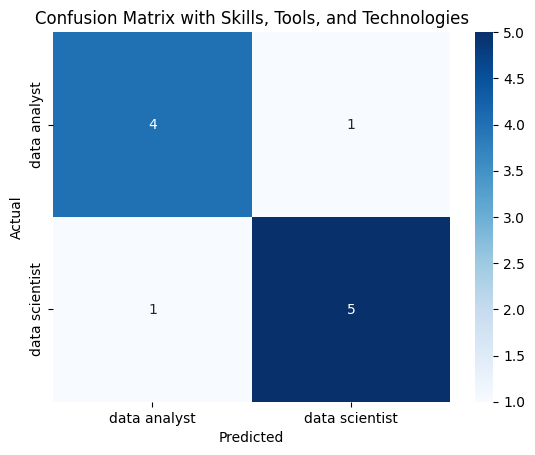

In [79]:
plt.Figure(figsize=(6,4))

sns.heatmap(confusion_matrix_v2, annot=True, fmt='d', cmap='Blues', xticklabels=model_v2.classes_, yticklabels=model_v2.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix with Skills, Tools, and Technologies')
plt.show()

## 3.15 Comparing Model Versions

## Observation

- The comparison table clearly shows that **Model V2** outperformed **Model V1** after adding **tools** and **technologies** as features.
- Overall accuracy improved from **0.64** to **0.82**, indicating stronger classification performance.
- **Data Analyst recall** increased significantly from **0.40** to **0.80**, showing that the enhanced model became much better at correctly identifying analyst roles.
- **Data Scientist recall** remained stable at **0.83**, meaning the improvement in analyst prediction did not negatively impact scientist classification.
- The comparison confirms that **feature engineering improved model balance and predictive quality without changing the underlying algorithm**.

In [80]:
report['data analyst']

{'precision': 0.6666666666666666,
 'recall': 0.4,
 'f1-score': 0.5,
 'support': 5.0}

In [81]:
pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Baseline Model': [accuracy, report['data analyst']['precision'], report['data analyst']['recall'], report['data analyst']['f1-score']],
    'Enhanced Model': [accuracy_v2, report_v2['data analyst']['precision'], report_v2['data analyst']['recall'], report_v2['data analyst']['f1-score']]
})

,Metric,Baseline Model,Enhanced Model
0,Accuracy,0.636364,0.818182
1,Precision,0.666667,0.800000
2,Recall,0.400000,0.800000
3,F1-Score,0.500000,0.800000


In [82]:
model_comparison_df = pd.DataFrame({
    'Metric': ['Accuracy',
               'Data Analyst Recall ', 
               'Data Scientist Recall',],
    'Baseline Model': [accuracy,
                report['data analyst']['recall'],
                report['data scientist']['recall']],
    'Enhanced Model': [accuracy_v2, 
                report_v2['data analyst']['recall'],
                report_v2['data scientist']['recall']]
})

model_comparison_df.round(2)

,Metric,Baseline Model,Enhanced Model
0,Accuracy,0.64,0.82
1,Data Analyst Recall,0.40,0.80
2,Data Scientist Recall,0.83,0.83


## 3.16 Visualizing Model Comparison

## Observation

- The model comparison visualization was improved by moving the legend outside the chart, preventing overlap with plotted data.
- Adding metric values directly on the bars increased readability and made performance differences easier to interpret.
- The enhanced visualization clearly communicates the improvement from the **Baseline Model** to the **Enhanced Model**, especially for **Data Analyst recall** and overall **accuracy**.
- Presentation-ready visualizations improve stakeholder understanding by making model performance easier to interpret than raw numbers alone.

In [83]:
model_comparison_long = model_comparison_df.melt(
    id_vars='Metric',
    var_name='Model',
    value_name='Score'
)
model_comparison_long

,Metric,Model,Score
0,Accuracy,Baseline Model,0.636364
1,Data Analyst Recall,Baseline Model,0.400000
2,Data Scientist Recall,Baseline Model,0.833333
3,Accuracy,Enhanced Model,0.818182
4,Data Analyst Recall,Enhanced Model,0.800000
5,Data Scientist Recall,Enhanced Model,0.833333


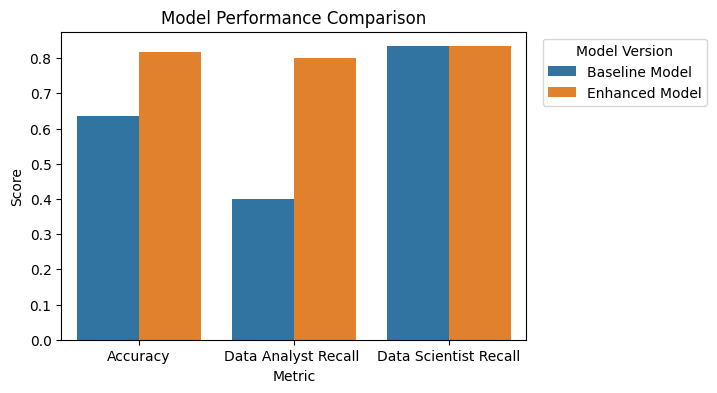

In [84]:
plt.figure(figsize=(6,4))

sns.barplot(data = model_comparison_long,
            x='Metric',
            y='Score',
            hue='Model')

plt.xlabel('Metric')
plt.ylabel('Score')
    
plt.legend(
    title='Model Version',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.title('Model Performance Comparison')
plt.show()

## 3.17 Testing the Enhanced Model on New Custom Profiles

## Observation

- The enhanced Logistic Regression model was successfully tested on multiple unseen custom profiles, simulating real-world prediction scenarios.
- A **Data Scientist-like profile** containing features such as **Python**, **Machine Learning**, **Deep Learning**, and **NLP** was correctly classified as **Data Scientist**.
- A **Data Analyst-like profile** emphasizing **SQL**, **Power BI**, and **Tableau** was correctly classified as **Data Analyst**.
- The results indicate that the enhanced model learned meaningful relationships between skills, tools, and technologies, improving prediction logic beyond the training dataset.
- This step validates the model’s ability to generalize and make consistent predictions on new user-defined inputs.

In [85]:
X.columns

Index(['python', 'r', 'sql', 'powerbi', 'tableau', 'deep learning',
       'machine learning', 'nlp'],
      dtype='str')

In [86]:
new_profile_v2 = pd.DataFrame({
    'python': [1],
    'r': [0],
    'sql': [1],
    'powerbi': [0],
    'tableau': [0],
    'deep learning': [1],
    'machine learning': [1],
    'nlp': [1]
})
new_profile_v2

,python,r,sql,powerbi,tableau,deep learning,machine learning,nlp
0,1,0,1,0,0,1,1,1


In [87]:
model_v2.predict(new_profile_v2)

array(['data scientist'], dtype=object)

In [88]:
new_profile_v3 = pd.DataFrame({
    'python': [1],
    'r': [0],
    'sql': [1],
    'powerbi': [1],
    'tableau': [1],
    'deep learning': [0],
    'machine learning': [0],
    'nlp': [0]
})
new_profile_v3

,python,r,sql,powerbi,tableau,deep learning,machine learning,nlp
0,1,0,1,1,1,0,0,0


In [89]:
model_v2.predict(new_profile_v3)

array(['data analyst'], dtype=object)

## 3.18 Understanding Feature Importance in the Enhanced Model

In [90]:
print(X.columns)
print(model_v2.coef_)
print(model_v2.classes_)

Index(['python', 'r', 'sql', 'powerbi', 'tableau', 'deep learning',
       'machine learning', 'nlp'],
      dtype='str')
[[ 0.98355619  0.24581729 -0.34018053 -0.3389344  -0.55780339  0.65506149
   2.19038482  0.66230248]]
['data analyst' 'data scientist']


In [91]:
model_coefficients_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model_v2.coef_[0]
})
model_coefficients_df

,feature,coefficient
0,python,0.983556
1,r,0.245817
2,sql,-0.340181
3,powerbi,-0.338934
4,tableau,-0.557803
5,deep learning,0.655061
6,machine learning,2.190385
7,nlp,0.662302


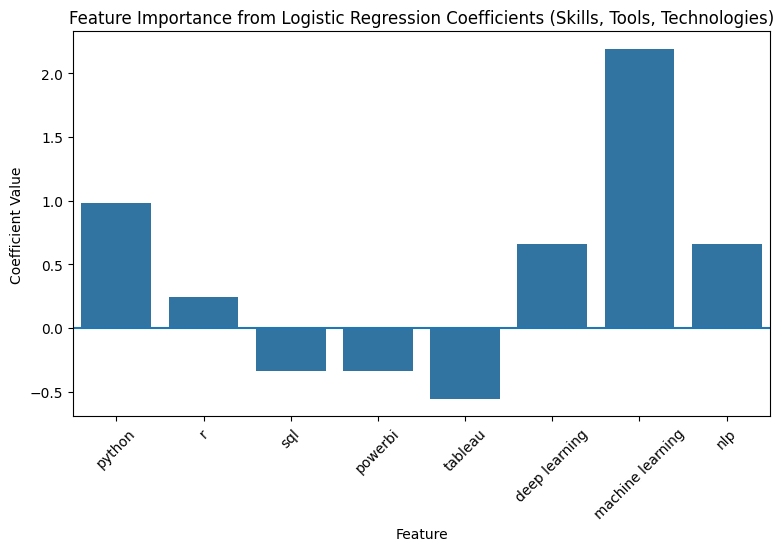

In [92]:
plt.figure(figsize=(9,5))

sns.barplot(data = model_coefficients_df,
            x='feature',
            y='coefficient')

plt.axhline(y=0)

plt.xlabel('Feature')
plt.ylabel('Coefficient Value')
plt.title('Feature Importance from Logistic Regression Coefficients (Skills, Tools, Technologies)')
plt.xticks(rotation=45)
plt.show()

## 3.19 Comparing Feature Importance: Baseline vs Enhanced Model

## Observation

- The feature importance comparison visualization highlights how model reasoning evolved after feature engineering.
- In the **Baseline Model**, **Python** had the strongest positive influence toward **Data Scientist** predictions due to the limited feature set.
- In the **Enhanced Model**, **Machine Learning** became the strongest predictive feature, while **Tableau** emerged as a strong indicator of **Data Analyst** roles.
- The influence of **Python** decreased in the enhanced model because additional features such as **Deep Learning**, **Machine Learning**, and **NLP** provided stronger explanatory signals.
- Comparing feature importance across model versions demonstrates how richer features improved interpretability and role differentiation.

In [93]:
baseline_coefficients_df = pd.DataFrame({
    'Feature': mlb_skills.classes_,
    'Coefficient': model.coef_[0],
    'Model': 'Baseline Model'
})

In [94]:
enhanced_coefficients_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model_v2.coef_[0],
    'Model': 'Enhanced Model'
})

In [95]:
feature_importance_comparison_df = pd.concat(
    [baseline_coefficients_df,
     enhanced_coefficients_df],
    axis=0
)

feature_importance_comparison_df

,Feature,Coefficient,Model
0,python,1.650856,Baseline Model
1,r,0.126728,Baseline Model
2,sql,-1.016455,Baseline Model
0,python,0.983556,Enhanced Model
1,r,0.245817,Enhanced Model
2,sql,-0.340181,Enhanced Model
3,powerbi,-0.338934,Enhanced Model
4,tableau,-0.557803,Enhanced Model
5,deep learning,0.655061,Enhanced Model
6,machine learning,2.190385,Enhanced Model


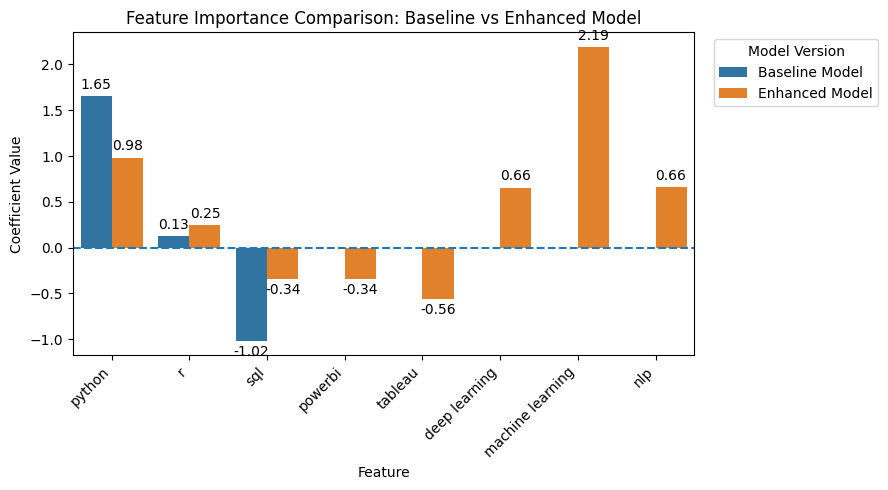

In [96]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=feature_importance_comparison_df,
    x='Feature',
    y='Coefficient',
    hue='Model'
)

# Reference line for positive vs negative influence
plt.axhline(y=0, linestyle='--')

# Show values on bars
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%.2f', padding=3)

plt.xlabel('Feature')
plt.ylabel('Coefficient Value')
plt.title('Feature Importance Comparison: Baseline vs Enhanced Model')

# Improve readability of feature names
plt.xticks(rotation=45, ha='right')

# Move legend outside chart
plt.legend(
    title='Model Version',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

# Prevent clipping
plt.tight_layout()

plt.show()

## 3.20 Saving the Final Model

## Observation

- The final enhanced Logistic Regression model was successfully saved using `joblib`.
- The model was saved inside the project-level `models/` directory, keeping trained ML assets organized professionally.
- The path issue occurred because the notebook was running from the `notebooks/` folder, so `../models/` was needed to access the project root.
- Saving the trained model allows future predictions without retraining the model from scratch.

In [ ]:
import joblib
joblib.dump(model_v2,
             '../models/job_role_classifier_v2.pkl')


['../models/job_role_classifier_v2.pkl']

## 3.21 Loading the Saved Model

## Observation

- The saved model was successfully loaded back into the notebook using `joblib.load()`.
- After deleting the original `model_v2` from memory, the loaded model was still able to generate predictions correctly.
- The loaded model predicted the custom Data Scientist-like profile as **Data Scientist**, confirming that the saved model file works as expected.
- This validates the full model persistence workflow: **train → save → load → predict**.

In [101]:
#del model_v2
loaded_model = joblib.load(
    '../models/job_role_classifier_v2.pkl'
)

loaded_model

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [102]:
loaded_model.predict(new_profile_v2)

array(['data scientist'], dtype=object)

## 3.22 Saving Required ML Assets for Future Predictions

## Observation

- The feature column schema was successfully saved and reloaded using `joblib`.
- Validation confirmed that the loaded feature columns exactly match `X.columns`, preserving the correct feature order used during training.
- Saving feature columns alongside the trained model ensures consistent preprocessing and prevents feature mismatch during future predictions.
- This step strengthens model reproducibility by allowing predictions to be generated with the same input structure used during training.

In [104]:
# Save feature order for future predictions
joblib.dump(
    X.columns,
    '../models/model_feature_columns.pkl'
)

['../models/model_feature_columns.pkl']

In [106]:
loaded_features_columns = joblib.load('../models/model_feature_columns.pkl')
print(loaded_features_columns)
print(X.columns)

Index(['python', 'r', 'sql', 'powerbi', 'tableau', 'deep learning',
       'machine learning', 'nlp'],
      dtype='str')
Index(['python', 'r', 'sql', 'powerbi', 'tableau', 'deep learning',
       'machine learning', 'nlp'],
      dtype='str')


## 3.23 Simulating a Real-World Prediction Workflow

## Observation

- A real-world prediction workflow was successfully simulated using the saved model and feature schema.
- Raw user input was automatically converted into a model-ready feature structure without manually encoding each feature.
- Dictionary comprehension and automatic feature mapping ensured consistency with the original training feature order.
- The loaded model successfully predicted the new profile as **Data Scientist**, validating the end-to-end prediction pipeline.
- This step demonstrates a production-style workflow where new inputs can be transformed and predicted automatically.

In [109]:
feature_dict = {
    feature: 0
    for feature in loaded_features_columns
}
feature_dict

{'python': 0,
 'r': 0,
 'sql': 0,
 'powerbi': 0,
 'tableau': 0,
 'deep learning': 0,
 'machine learning': 0,
 'nlp': 0}

In [110]:
new_skills = [
    'python',
    'sql',
    'machine learning'
]

for skill in new_skills:
    feature_dict[skill] = 1

feature_dict


{'python': 1,
 'r': 0,
 'sql': 1,
 'powerbi': 0,
 'tableau': 0,
 'deep learning': 0,
 'machine learning': 1,
 'nlp': 0}

In [111]:
new_profile_df = pd.DataFrame([feature_dict])
new_profile_df

,python,r,sql,powerbi,tableau,deep learning,machine learning,nlp
0,1,0,1,0,0,0,1,0


In [112]:
loaded_model.predict(new_profile_df)

array(['data scientist'], dtype=object)

## 3.24 Creating a Reusable Prediction Function

## Observation

- A reusable prediction function was successfully created to automate the full prediction workflow.
- The function automatically converts raw user skills into the correct model-ready feature structure, removing the need for manual encoding.
- Input normalization using `.lower()` improved robustness by allowing predictions from uppercase, lowercase, or mixed-case user inputs.
- Unknown or unsupported skills are safely ignored, preventing prediction failures and improving usability.
- This step transforms the project from a manual ML experiment into a reusable and production-style prediction pipeline.

In [115]:
def predict_job_role_for_profile(skills):
    feature_dict = {
    feature: 0
    for feature in loaded_features_columns
}
    for skill in skills:
        skill= skill.lower()
        if skill in feature_dict:
            feature_dict[skill] = 1
    new_profile_df = pd.DataFrame([feature_dict])
    return loaded_model.predict(new_profile_df)[0]

In [117]:
predict_job_role_for_profile([
    'Python',
    'SQL',
    'Machine Learning'
])

'data scientist'

In [116]:
predict_job_role_for_profile([
    'SQL',
    'PowerBI',
    'TABLEAU'
])

'data analyst'

## 3.25 Final ML Pipeline Summary

## Final ML Pipeline Summary

In this machine learning phase, a complete end-to-end job role classification pipeline was developed to distinguish between **Data Analyst** and **Data Scientist** roles based on extracted job posting features.

The workflow started by transforming extracted **skills**, **tools**, and **technologies** into machine-readable numerical features using **MultiLabelBinarizer**, enabling machine learning models to process textual information.

A **baseline Logistic Regression model** was first trained using only skills-based features. After evaluating its performance, weaknesses were identified, particularly in predicting **Data Analyst** roles. To improve performance, **feature engineering** was applied by incorporating additional **tools** and **technologies** into the feature set.

The enhanced model achieved significantly better performance, improving accuracy from **0.64** to **0.82**, while also producing more balanced classification results across both job roles. Feature importance analysis showed that **Machine Learning** became the strongest indicator of **Data Scientist** roles, while **Tableau** strongly influenced **Data Analyst** predictions.

To simulate real-world machine learning practices, the final model was saved using **joblib**, reloaded successfully, and tested on unseen custom profiles. Finally, a reusable prediction function was developed to automatically transform user-provided skills into the required model format and generate predictions, making the workflow more scalable and production-ready.